# 01 - Exploration des données (EDA)

**Objectif du projet** : classifier une IRM cérébrale en 4 catégories : *glioma*, *meningioma*, *pituitary*, *notumor*.

**Dataset** : [Brain Tumor MRI Dataset (Kaggle)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)

Ce notebook répond à la 1re partie de l'étape 1 du sujet : **explorer le dataset** pour justifier les choix de prétraitement (notebook `02-preproc`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")

## 1. Chargement
Le dataset est téléchargé via `kagglehub` (mis en cache localement après le 1er téléchargement).

In [2]:
from load_data import CLASS_NAMES, list_images, load_brain_tumor_data

DATA = load_brain_tumor_data()
rows = []
for split in ["Training", "Testing"]:
    paths, labels = list_images(DATA, split)
    for p, y in zip(paths, labels):
        rows.append({"split": split, "classe": CLASS_NAMES[y], "path": p})
df = pd.DataFrame(rows)
print(DATA)
df.head()

C:\Users\araba\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\araba\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2


,split,classe,path
0,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
1,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
2,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
3,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
4,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...


## 2. Répartition des classes

split,Testing,Training,Total
classe,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800


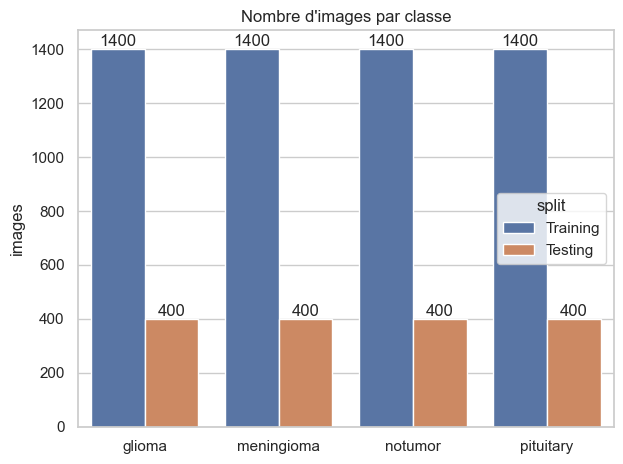

In [3]:
counts = df.pivot_table(index="classe", columns="split", values="path", aggfunc="count")
counts["Total"] = counts.sum(axis=1)
display(counts)

ax = sns.countplot(data=df, x="classe", hue="split", order=CLASS_NAMES)
ax.set(title="Nombre d'images par classe", xlabel="", ylabel="images")
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout(); plt.savefig(FIG / "eda_class_distribution.png", dpi=150); plt.show()

**Constat** : le dataset est **parfaitement équilibré** (1 400 images par classe en Training, 400 en Testing).
- Pas besoin de pondérer la loss ni de sur-échantillonner.
- L'*accuracy* est donc une métrique pertinente (une classe ne peut pas « gonfler » le score).

## 3. Format et taille des images

In [4]:
def info(p):
    im = Image.open(p)
    return pd.Series({"largeur": im.width, "hauteur": im.height, "mode": im.mode})

df = pd.concat([df, df["path"].apply(info)], axis=1)
print("Modes couleur :", df["mode"].value_counts().to_dict())
print("Nombre de tailles différentes :", df.groupby(["largeur", "hauteur"]).ngroups)
display(df[["largeur", "hauteur"]].describe().round(0))
display(df.groupby(["largeur", "hauteur"]).size().sort_values(ascending=False).head(5).rename("images"))

Modes couleur : {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}
Nombre de tailles différentes : 447


,largeur,hauteur
count,7200.0,7200.0
mean,453.0,457.0
std,130.0,124.0
min,150.0,167.0
25%,442.0,449.0
50%,512.0,512.0
75%,512.0,512.0
max,1375.0,1446.0


largeur  hauteur
512      512        5014
225      225         338
630      630          90
201      251          57
228      221          51
Name: images, dtype: int64

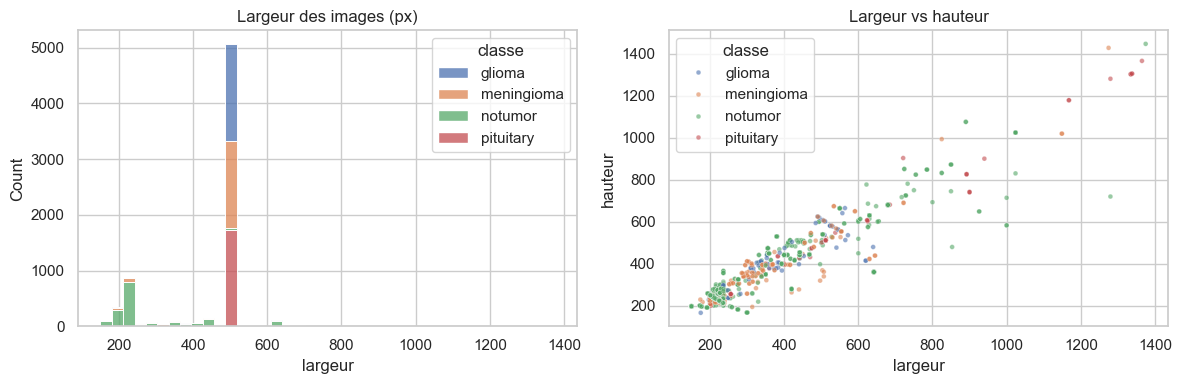

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df, x="largeur", hue="classe", bins=40, ax=axes[0], multiple="stack")
axes[0].set_title("Largeur des images (px)")
sns.scatterplot(df, x="largeur", y="hauteur", hue="classe", s=12, alpha=0.6, ax=axes[1])
axes[1].set_title("Largeur vs hauteur")
plt.tight_layout(); plt.savefig(FIG / "eda_image_sizes.png", dpi=150); plt.show()

**Constats** :
- **~450 tailles différentes**, de ~150 px à ~1 400 px ; la grande majorité fait **512×512**. Certaines ne sont pas carrées.
  → il faut **redimensionner à une taille fixe** (un CNN a besoin d'entrées de même taille).
- Les fichiers sont enregistrés dans des modes mélangés (`L` = niveaux de gris, `RGB` = couleur, quelques `RGBA`/`P`). Le mode dit seulement **comment le fichier est stocké**, pas ce qu'il contient : on regarde les images juste en dessous pour trancher.

## 4. Exemples par classe

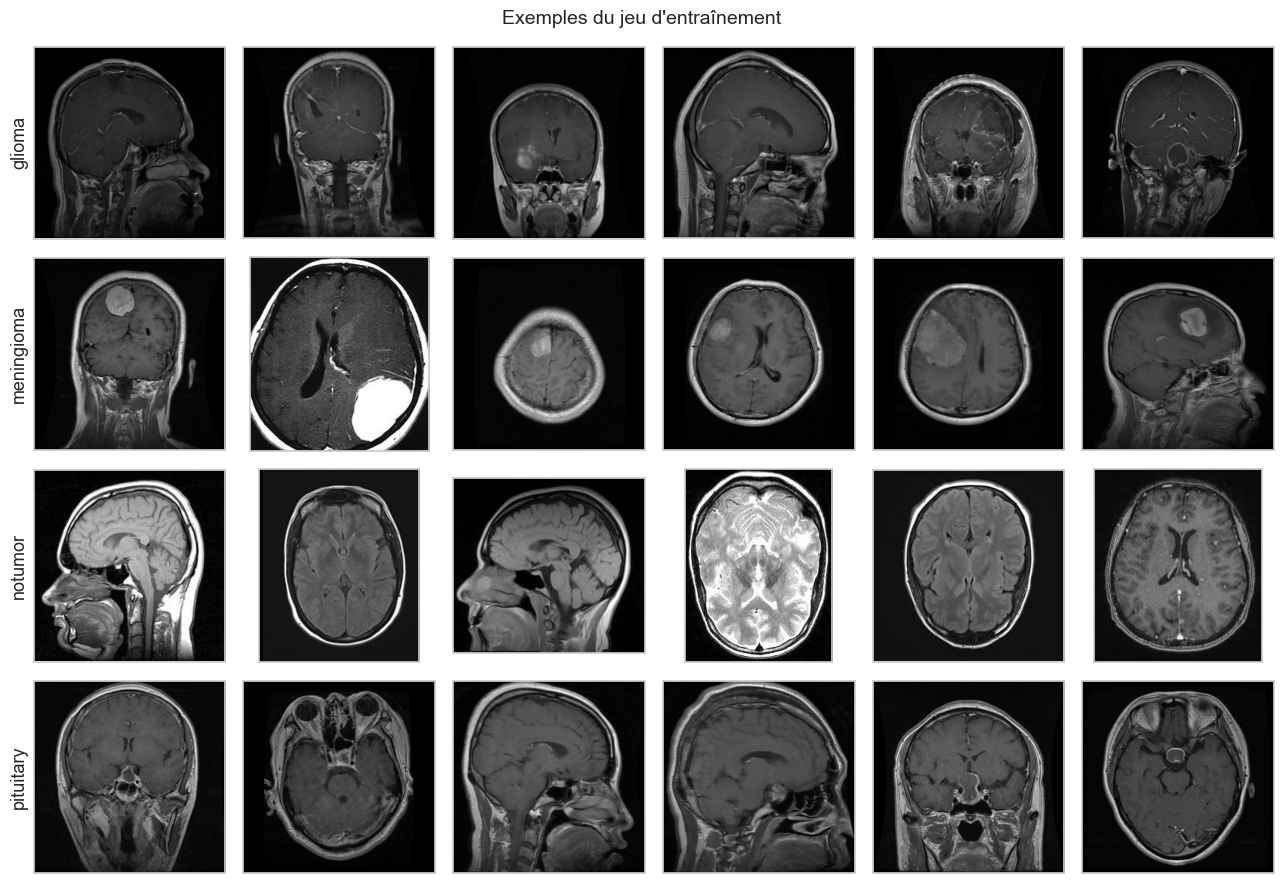

In [6]:
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for r, name in enumerate(CLASS_NAMES):
    for c, p in enumerate(df[(df.classe == name) & (df.split == "Training")].sample(6, random_state=1).path):
        axes[r, c].imshow(Image.open(p).convert("RGB"))  # affichée telle quelle, sans passage en gris
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=13)
plt.suptitle("Exemples du jeu d'entraînement", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "eda_samples.png", dpi=150); plt.show()

**Constats** :
- Les images sont affichées **telles quelles** (sans conversion en gris), y compris celles stockées en `RGB` : **aucune ne présente de couleur**. C'est normal : une IRM mesure **un seul signal par pixel** ; le RGB n'est qu'un format d'enregistrement où les 3 canaux portent la même valeur.
  → **décision : 1 canal**. Garder 3 canaux identiques n'apporterait aucune information et triplerait le calcul de la 1re couche.
- Plusieurs **plans de coupe** (axial, coronal, sagittal) et **séquences IRM** (T1, T2…) sont mélangés : le modèle doit généraliser à tous.
- Beaucoup d'images ont de **larges bords noirs** autour du crâne, et le cerveau n'occupe pas toujours la même place.
  → on **recadre sur le cerveau** avant de redimensionner, pour ne pas gaspiller de pixels.
- Certaines tumeurs (surtout *pituitary*) sont **petites** : il ne faut pas trop réduire la résolution.

## 5. Intensité des pixels

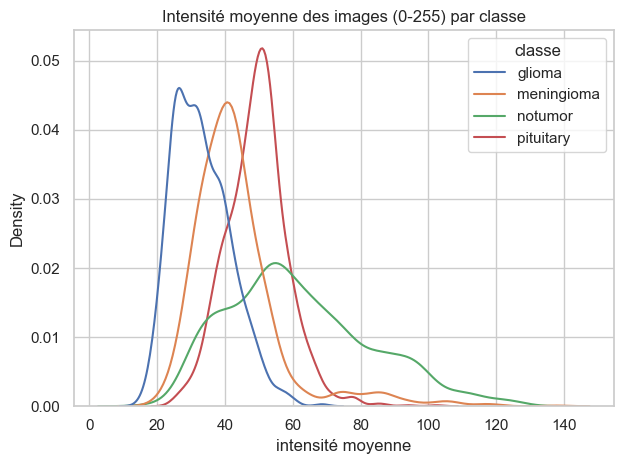

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
glioma,1400.0,33.1,8.5,14.9,26.2,31.9,38.8,68.8
meningioma,1400.0,43.4,13.8,18.2,35.1,41.0,47.0,137.8
notumor,1400.0,61.7,21.1,17.4,46.4,57.8,75.2,125.1
pituitary,1400.0,49.4,9.0,24.7,43.7,49.7,54.4,102.3


In [7]:
def mean_intensity(p):
    return np.asarray(Image.open(p).convert("L"), dtype=np.float32).mean()

train_df = df[df.split == "Training"].copy()
train_df["intensité moyenne"] = train_df["path"].apply(mean_intensity)
ax = sns.kdeplot(train_df, x="intensité moyenne", hue="classe", common_norm=False)
ax.set_title("Intensité moyenne des images (0-255) par classe")
plt.tight_layout(); plt.savefig(FIG / "eda_intensity.png", dpi=150); plt.show()
train_df.groupby("classe")["intensité moyenne"].describe().round(1)

**Constat** : les intensités varient beaucoup d'une image à l'autre (machines et séquences différentes), et sont sur une échelle 0-255.
→ on **normalise** : division par 255 puis standardisation avec la moyenne et l'écart-type **du jeu d'entraînement**. Des entrées centrées et réduites stabilisent la descente de gradient.
→ on ajoute une **légère augmentation de luminosité/contraste** pendant l'entraînement pour rendre le modèle robuste à ces variations.

## 6. Doublons

In [8]:
import hashlib

df["hash"] = df["path"].apply(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())
groups = df.groupby("hash").agg(n=("path", "size"), splits=("split", "nunique"), classes=("classe", "nunique"))
dups = groups[groups.n > 1]
print(f"Groupes de doublons exacts : {len(dups)}  ({dups.n.sum()} images concernées)")
print(f"  - entre Training et Testing : {(dups.splits > 1).sum()}")
print(f"  - avec des labels différents : {(dups.classes > 1).sum()}")
df[df.hash.isin(dups.index)].groupby(["split", "classe"]).size().rename("images en double")

Groupes de doublons exacts : 153  (340 images concernées)
  - entre Training et Testing : 0
  - avec des labels différents : 0


split     classe    
Testing   glioma         27
          meningioma      4
Training  meningioma     27
          notumor       216
          pituitary      66
Name: images en double, dtype: int64

**Constat** : il y a des **doublons exacts** à l'intérieur des splits, mais **aucun entre Training et Testing** et **aucun conflit de label**.
→ on supprime les doublons de Training **avant** de le découper en train/validation : sinon une même image pourrait être à la fois en train et en validation, ce qui gonflerait artificiellement le score de validation.
→ on garde Testing tel quel (c'est le jeu de test officiel).

## 7. Bilan → choix de prétraitement

| Constat | Choix |
|---|---|
| Tailles très variables (150 → 1 400 px, majorité 512) | Redimensionnement à **224×224** : assez de détail pour les petites tumeurs, coût de calcul raisonnable, taille standard en vision |
| Images non carrées | **Padding** noir jusqu'à un carré avant redimensionnement (pas de déformation) |
| Larges bords noirs | **Recadrage** automatique sur le cerveau |
| Aucune couleur visible sur les images (une IRM est monochrome) | **1 canal** |
| Intensités 0-255 très variables | **/255 puis standardisation** (moyenne/écart-type du train) |
| Classes équilibrées | Pas de pondération ; accuracy pertinente |
| Doublons dans Training | **Suppression** avant le découpage train/validation |
| Pas de jeu de validation fourni | **15 % de Training** (stratifié) pour les callbacks et l'optimisation ; Testing réservé à l'évaluation finale |

La mise en œuvre est dans `src/load_data.py` et illustrée dans `02-preproc.ipynb`.